# Week 3 — Pixel neighborhood k×k + Conv encoder

Centered **k×k** AlphaEarth windows (default **k=3**) with a small Conv encoder:

- Input `(65, k, k)` = 64 AE bands + validity mask
- `Conv→BN→ReLU` ×2 → masked GAP → `Linear→3`
- **Classifier:** hard labels + ROS + CE
- **Regression:** soft `frac_*_full` + ROS + softmax MSE + decode (`τ=0.15`)

Compare to single-pixel notebook 05 (`outputs/week3_pixel_3class/`).


## Results (cached)


{
  "name": "week3_pixel_neighborhood_k3_cnn",
  "k": 3,
  "encoder": "NbCNN",
  "emb_dim": 128,
  "epochs": 40,
  "n_gpu": 8,
  "n_pixels": 308675,
  "building_share_max": 0.15,
  "clf_targets": "hard_label_ros",
  "reg_targets": "soft_frac_ros",
  "label_counts": {
    "non_residential": 250342,
    "residential": 29366,
    "empty": 28967
  },
  "clf_loro_macro_f1_mean": 0.3454445308190508,
  "clf_loro_macro_f1_std": 0.12599842589481983,
  "reg_loro_macro_f1_mean": 0.32422182570598745,
  "reg_loro_macro_f1_std": 0.10115118262265518,
  "oof_clf_macro_f1": 0.3533789223291353,
  "oof_reg_macro_f1": 0.33404010130942874,
  "reg_beats_clf_metros": 4,
  "baseline_single_pixel": {
    "oof_clf_macro_f1": 0.4572393799964856,
    "oof_reg_macro_f1": 0.5211295030279147,
    "clf_loro_macro_f1_mean": 0.4462323300607064,
    "reg_loro_macro_f1_mean": 0.5030133981804403
  }
}


**oof_confusion_clf_vs_reg.png**

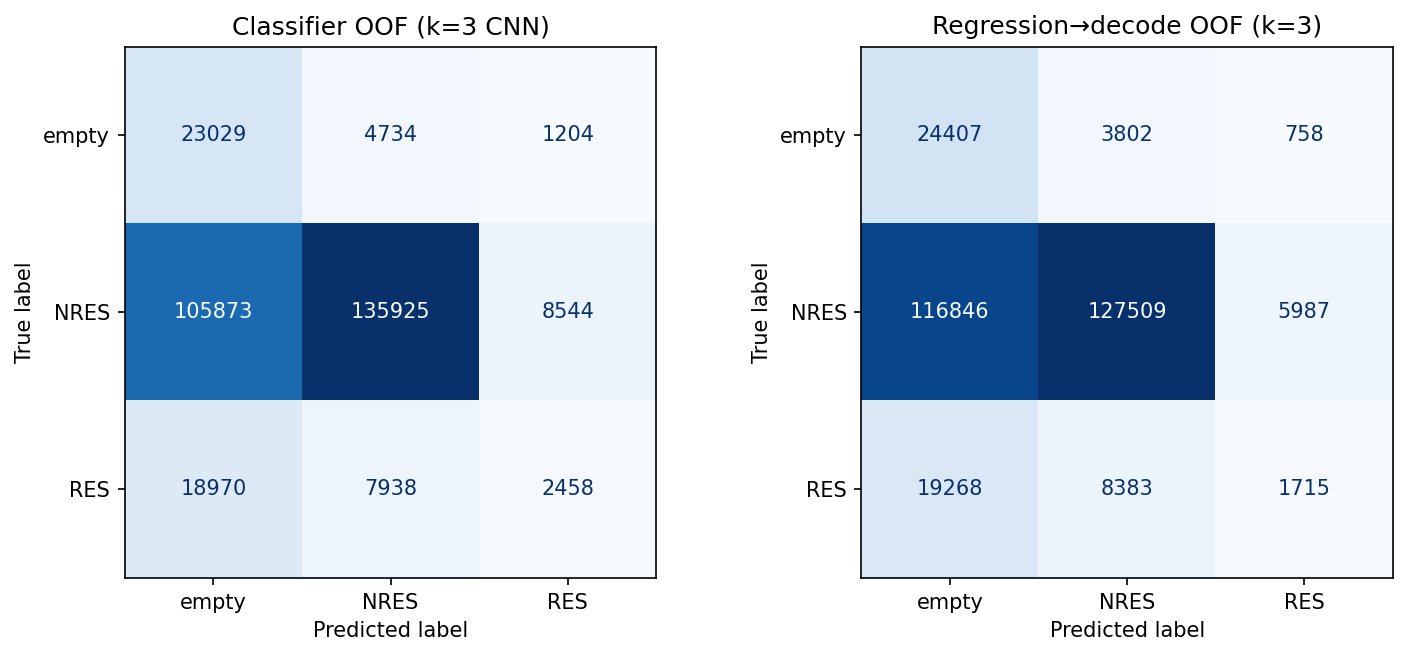

**loro_f1_clf_vs_reg.png**

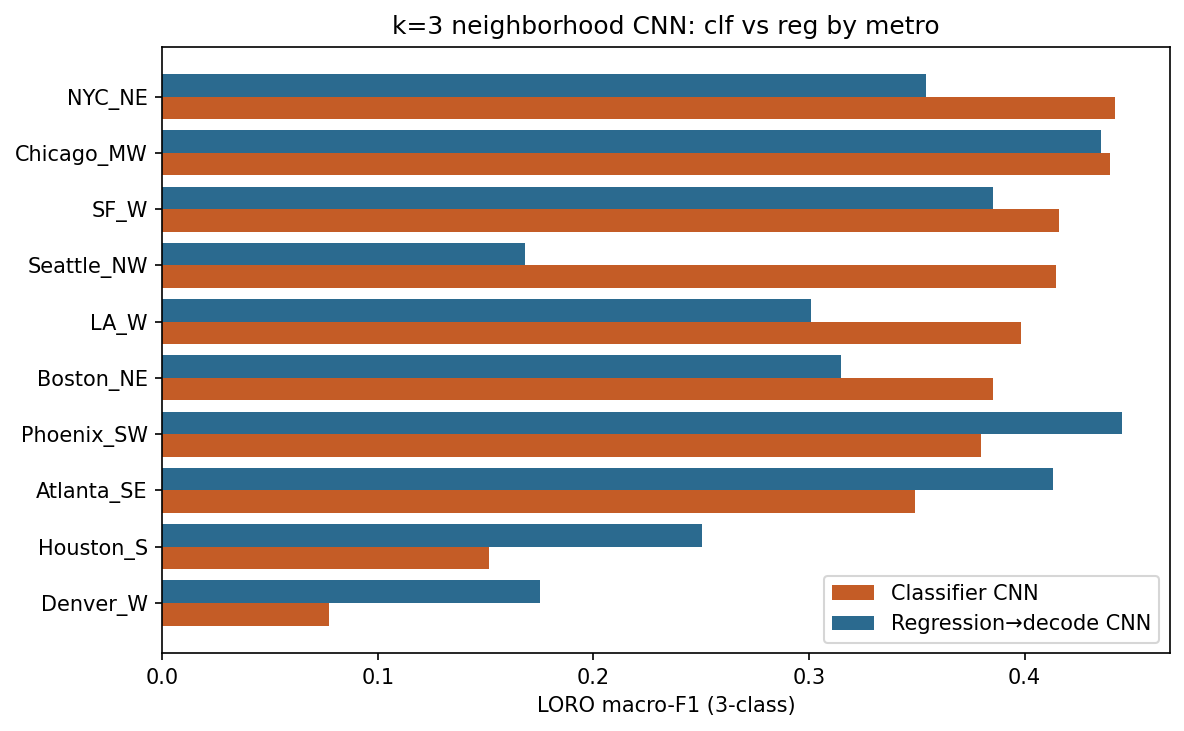

**delta_reg_minus_clf_by_city.png**

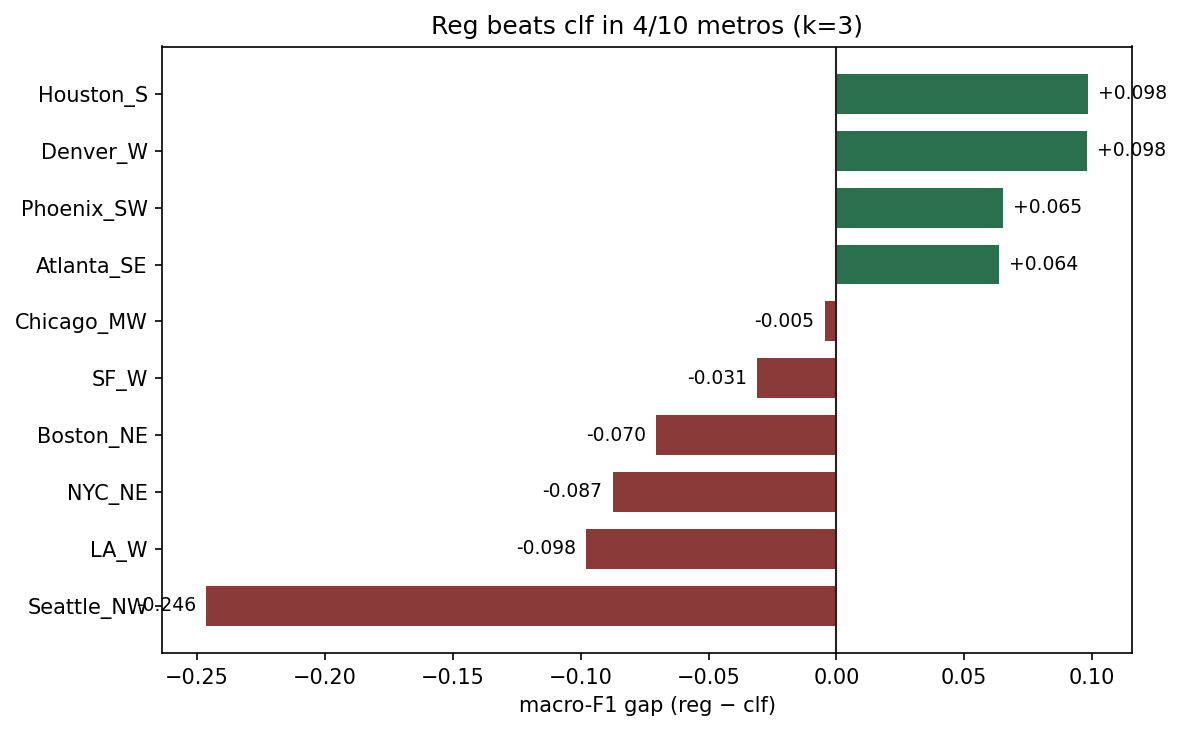

**umap_clf_by_label_per_region.png**

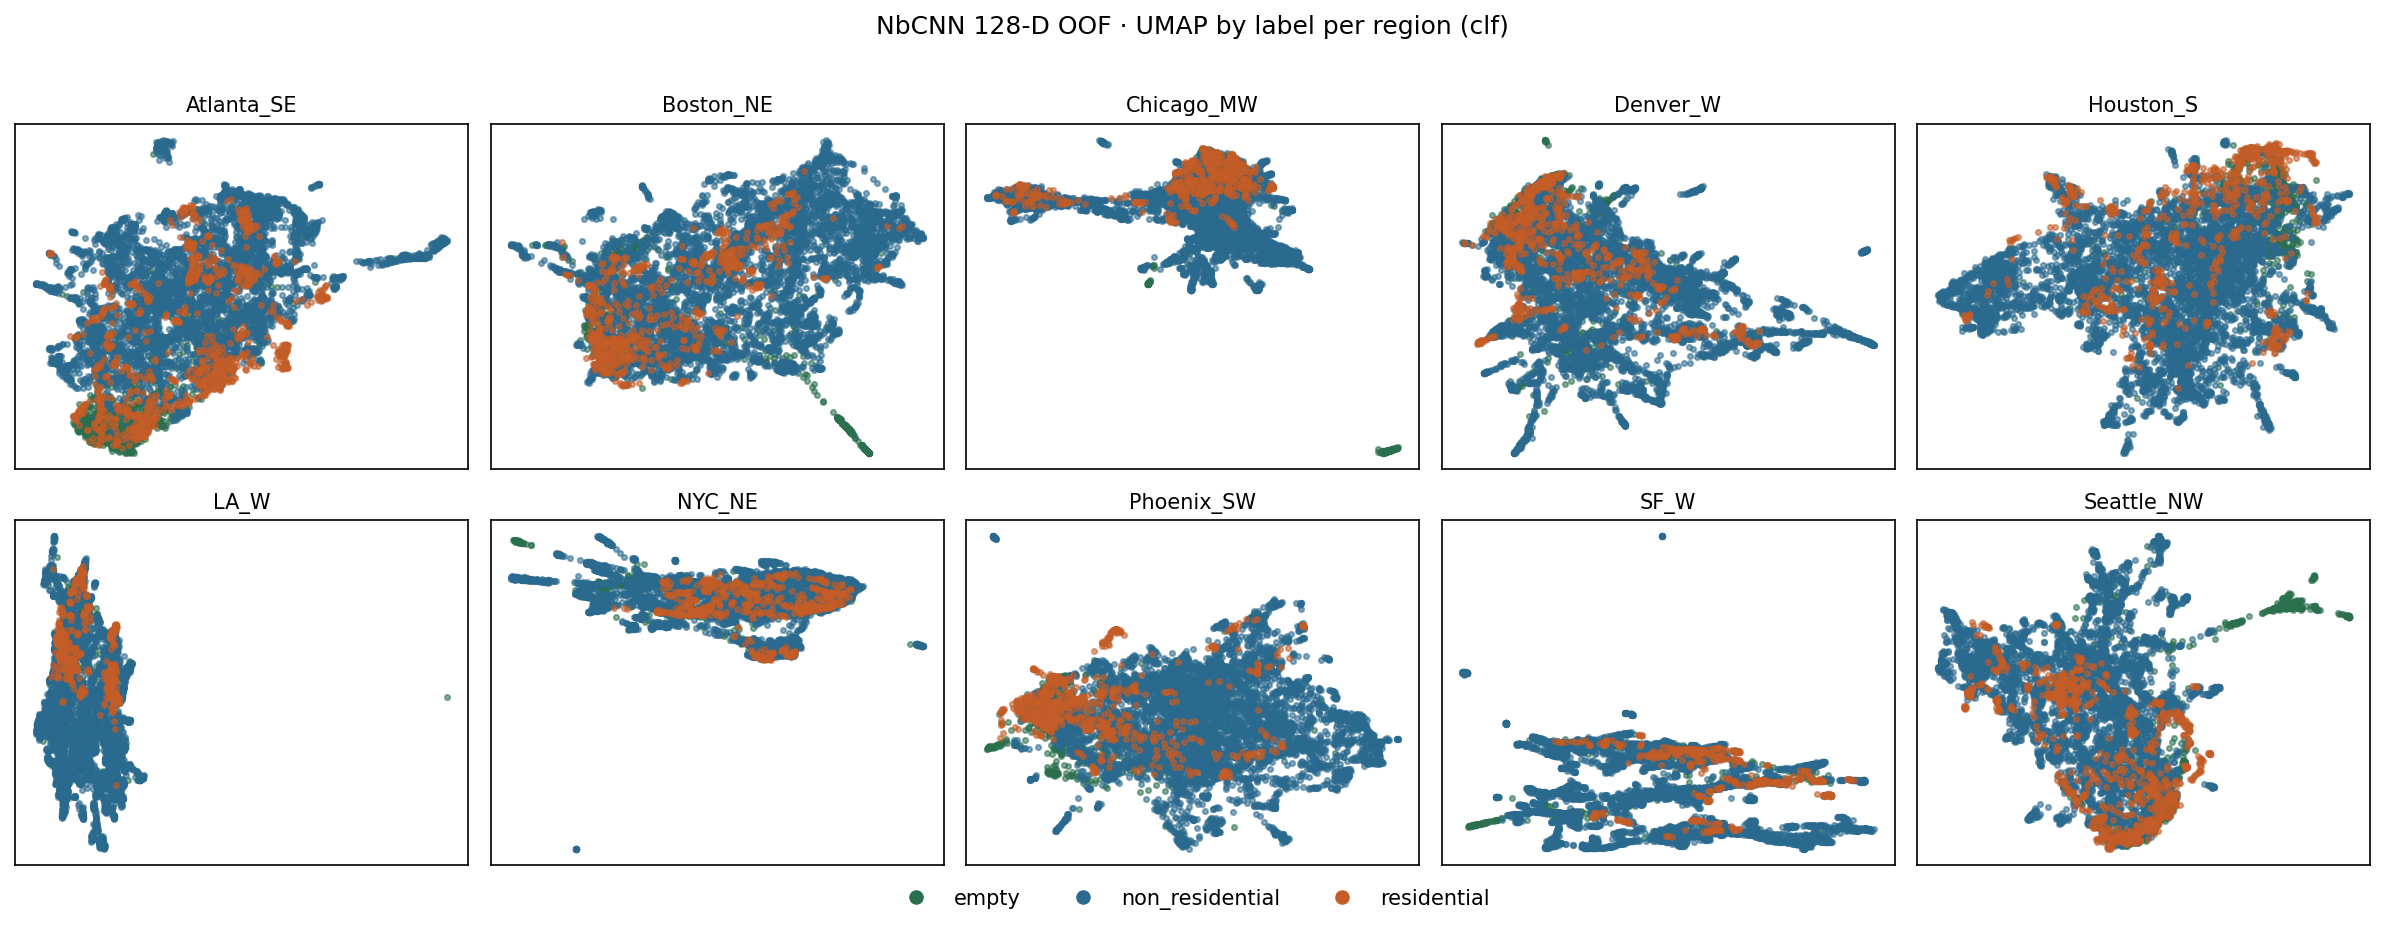

**umap_reg_by_label_per_region.png**

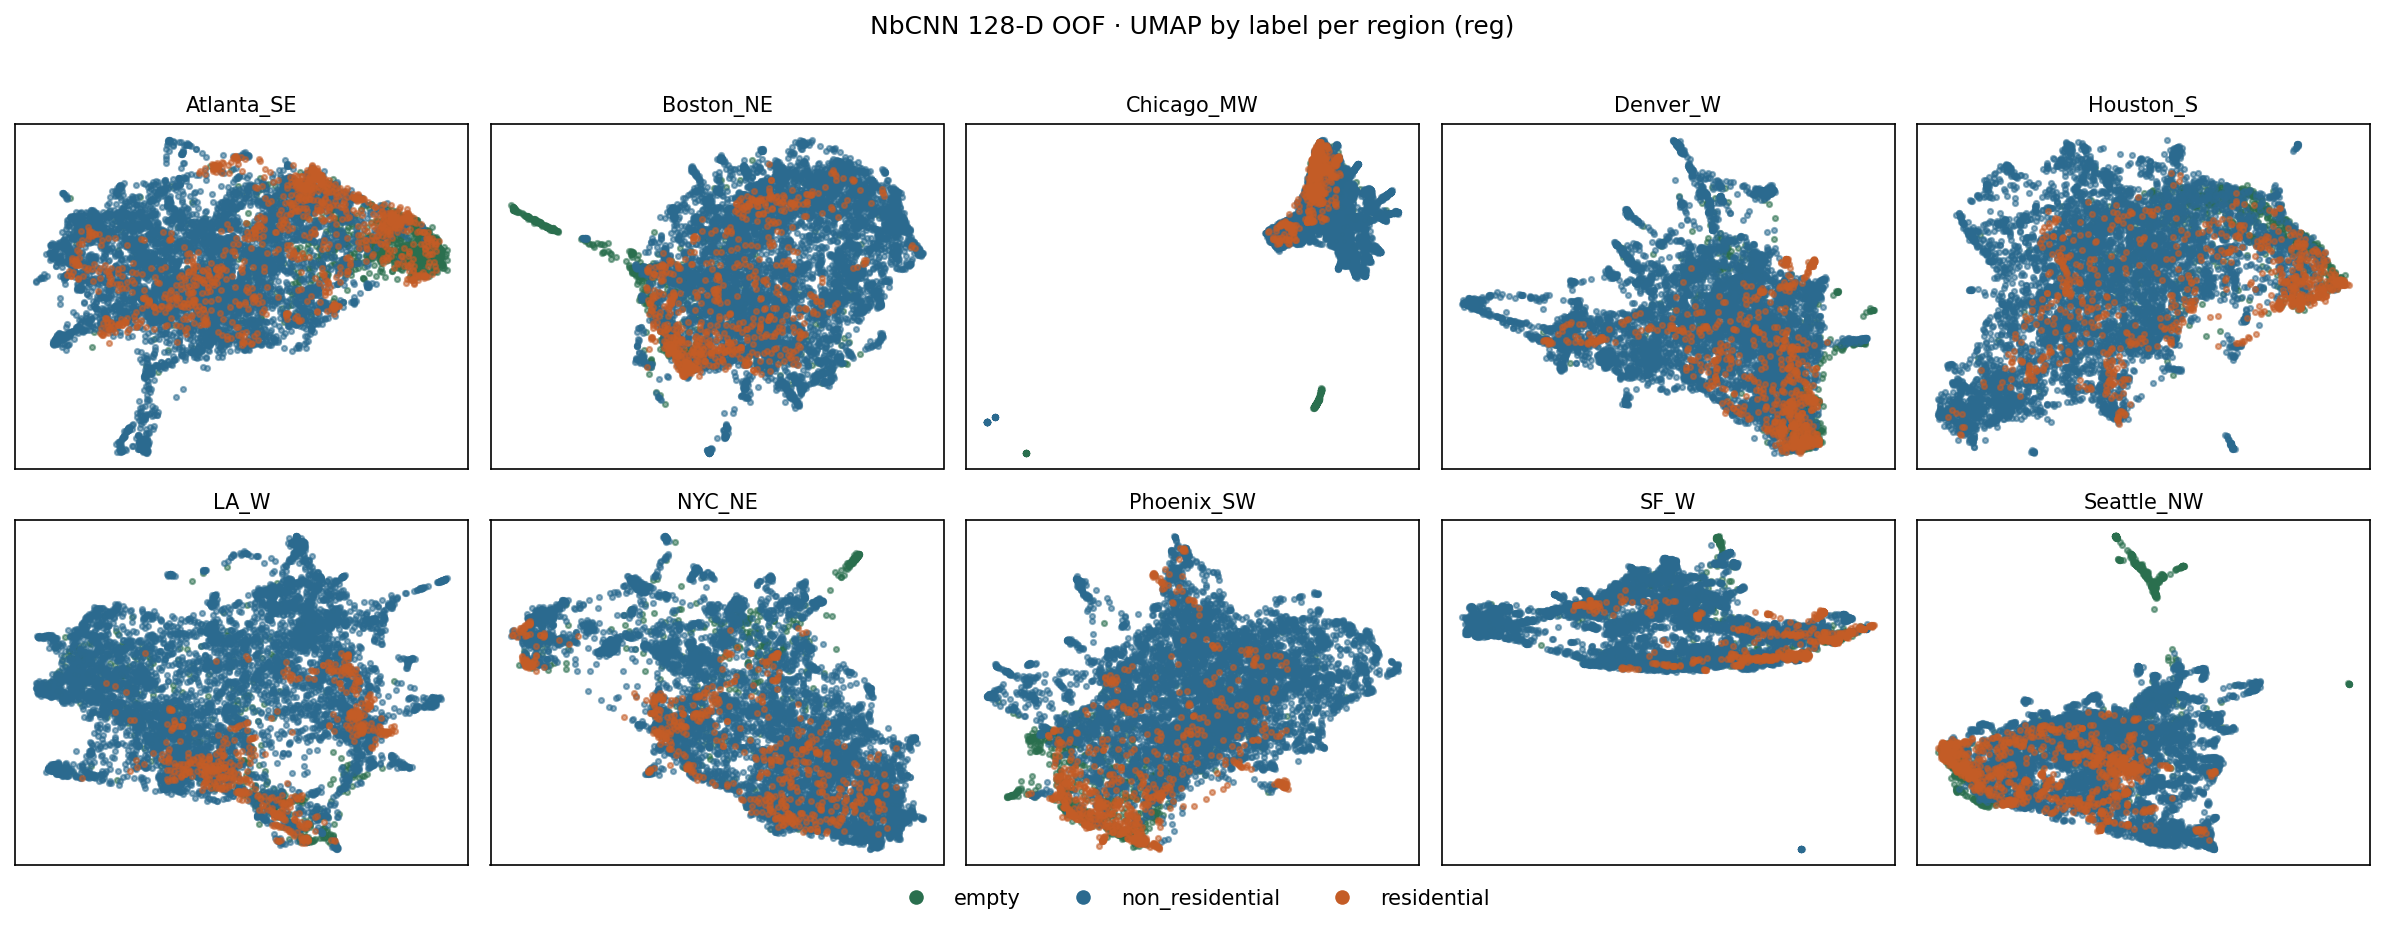

**pca_clf_overview.png**

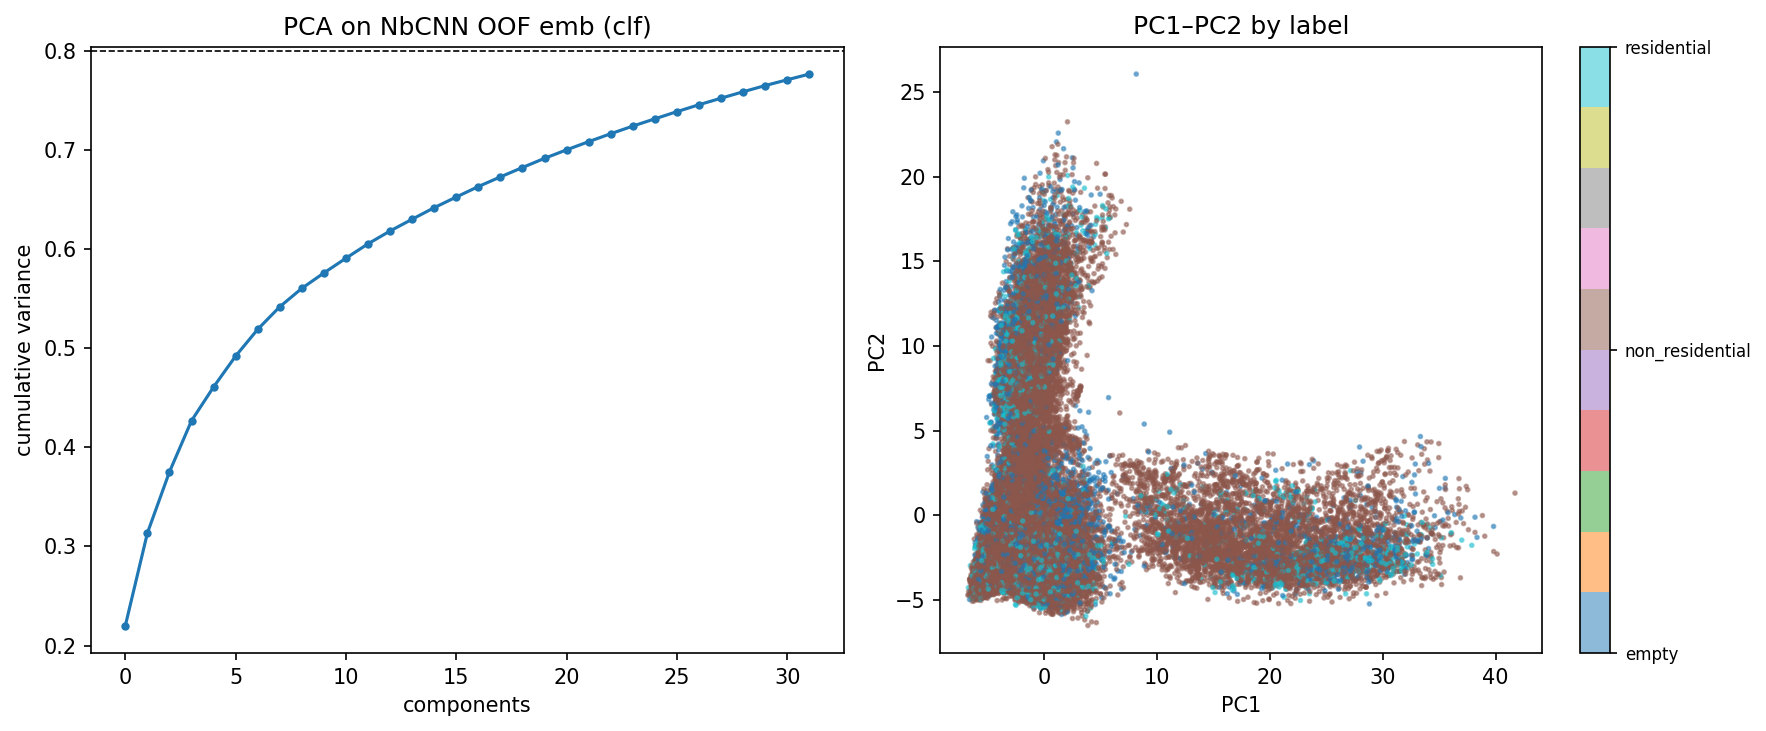

**pca_reg_overview.png**

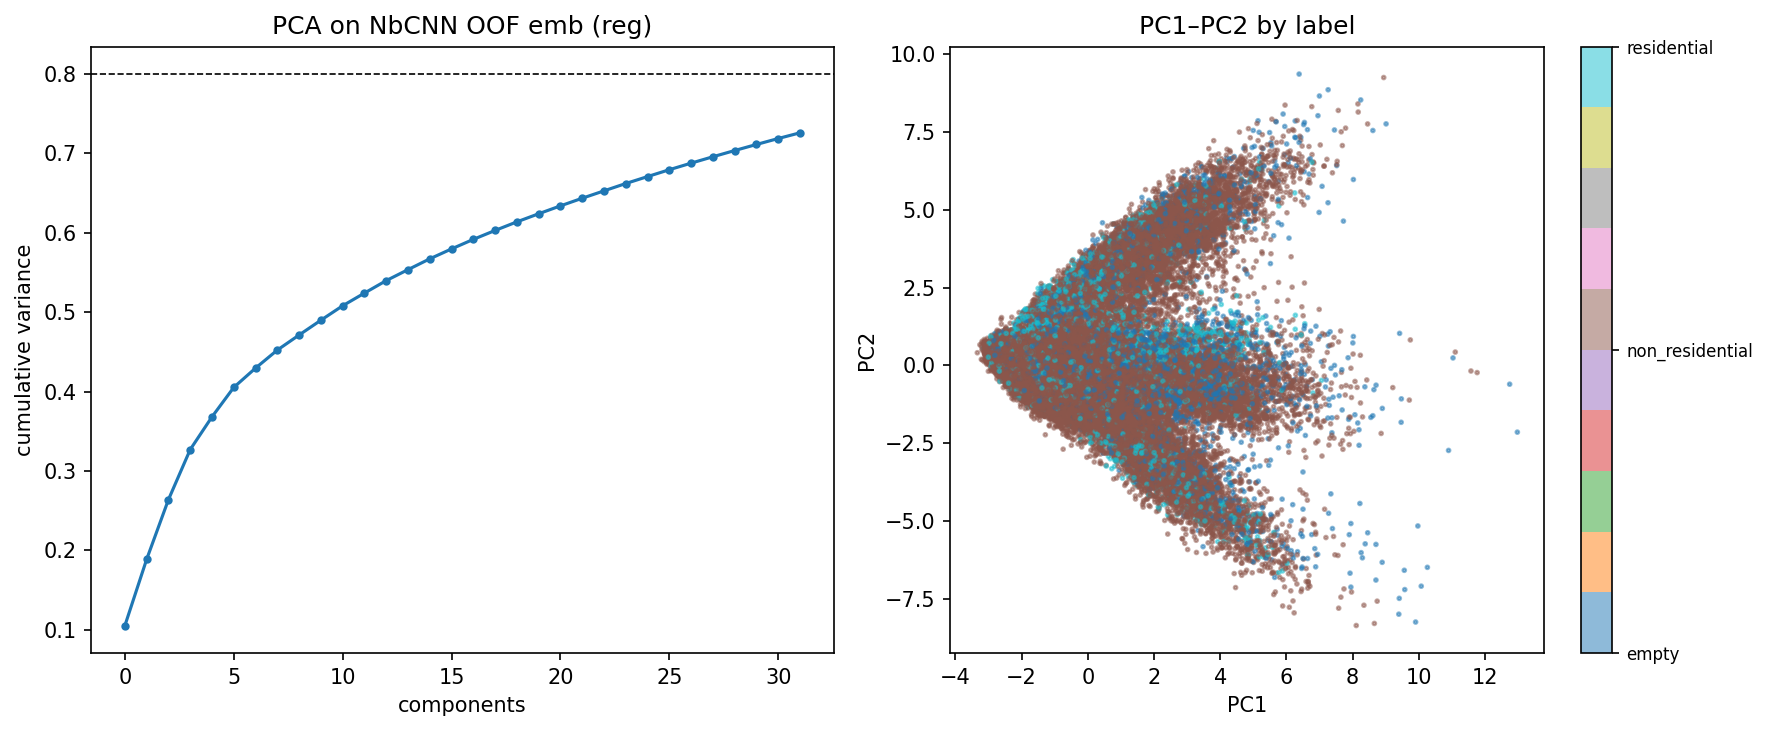

### Per-region UMAP (clf)

**Atlanta_SE**

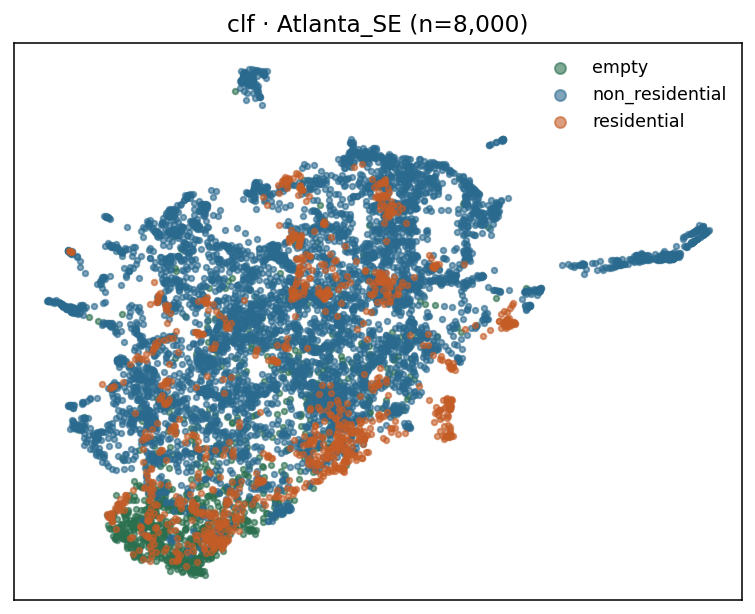

**Boston_NE**

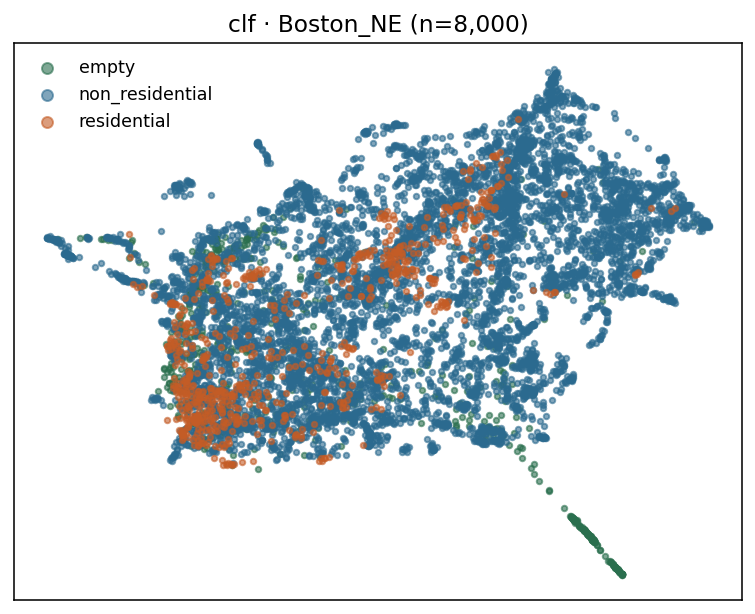

**Chicago_MW**

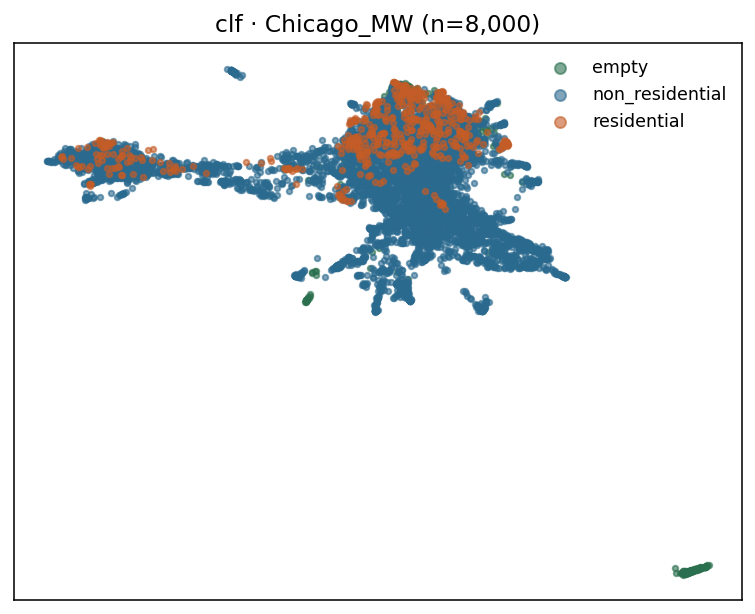

**Denver_W**

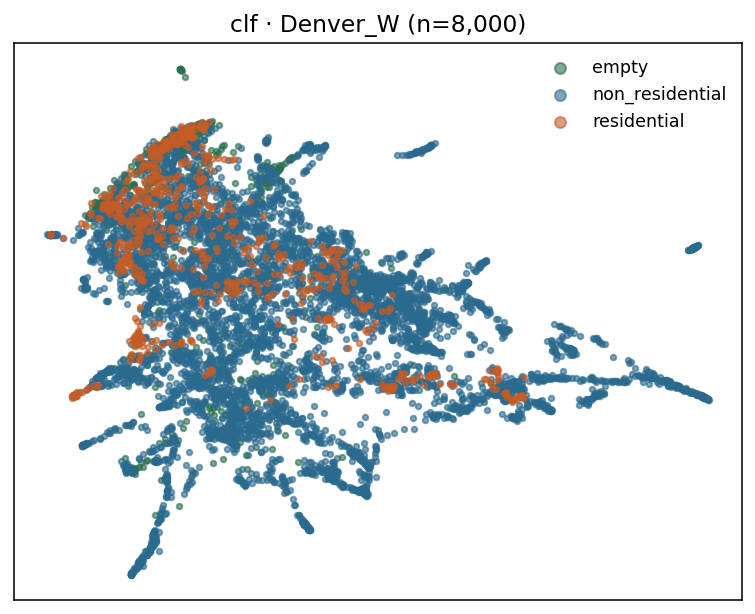

**Houston_S**

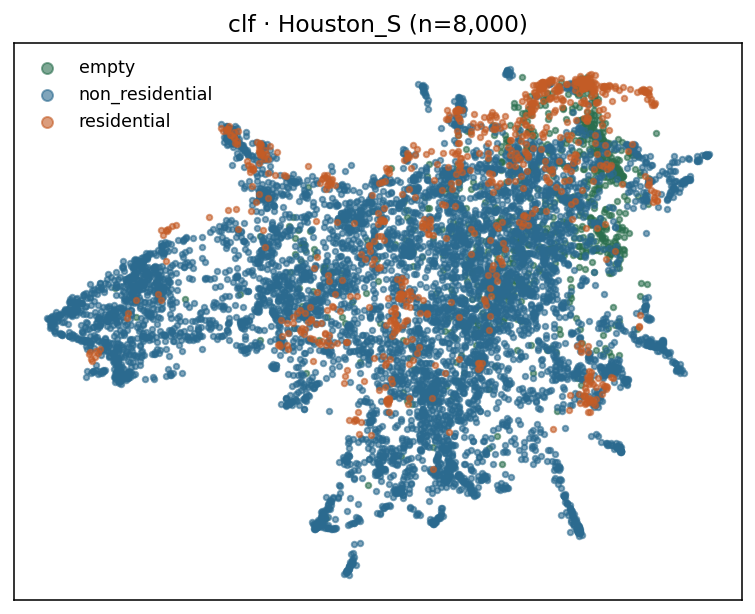

**LA_W**

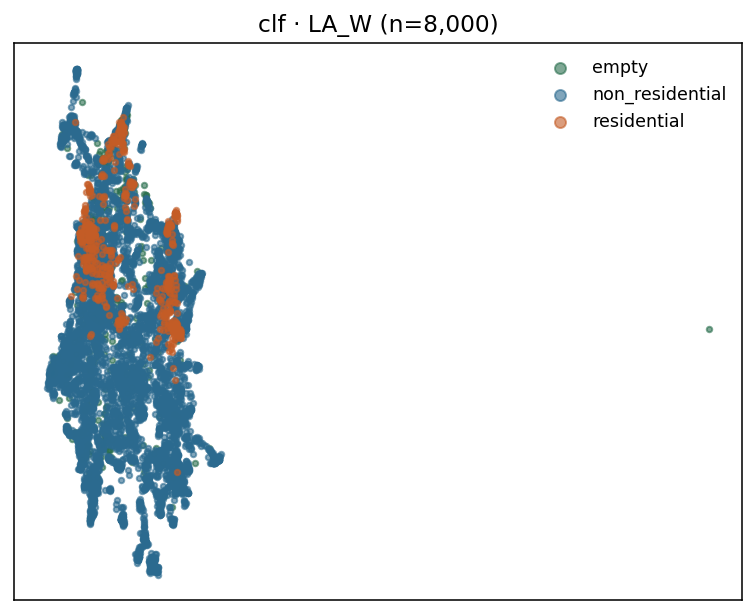

**NYC_NE**

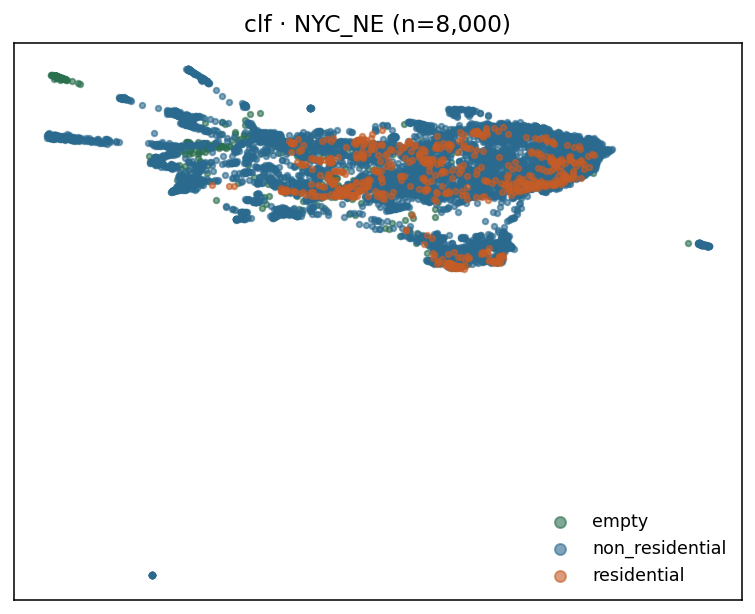

**Phoenix_SW**

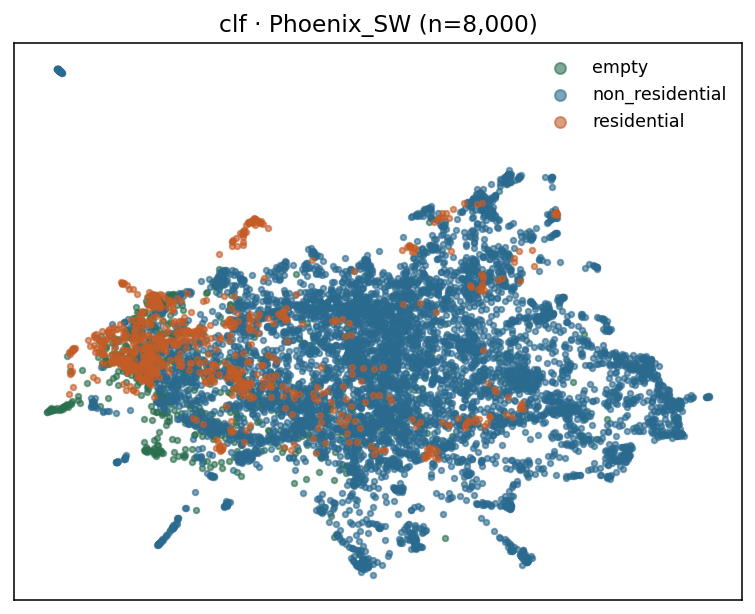

**SF_W**

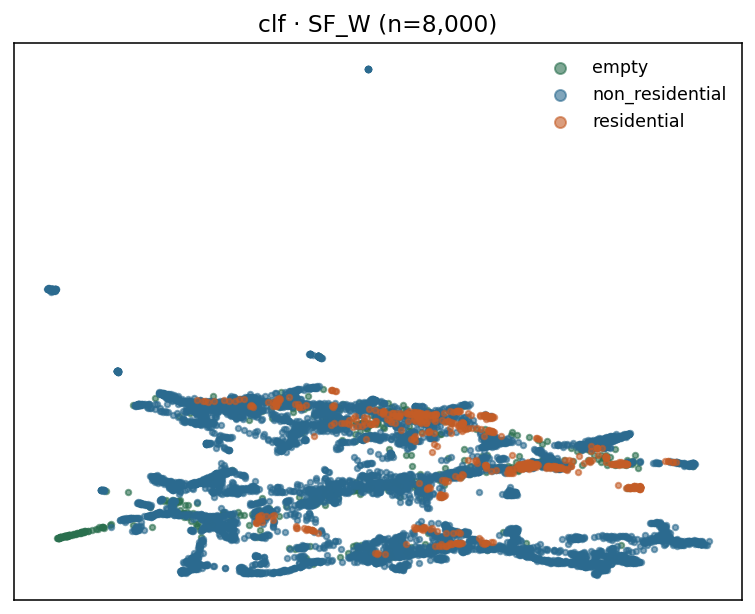

**Seattle_NW**

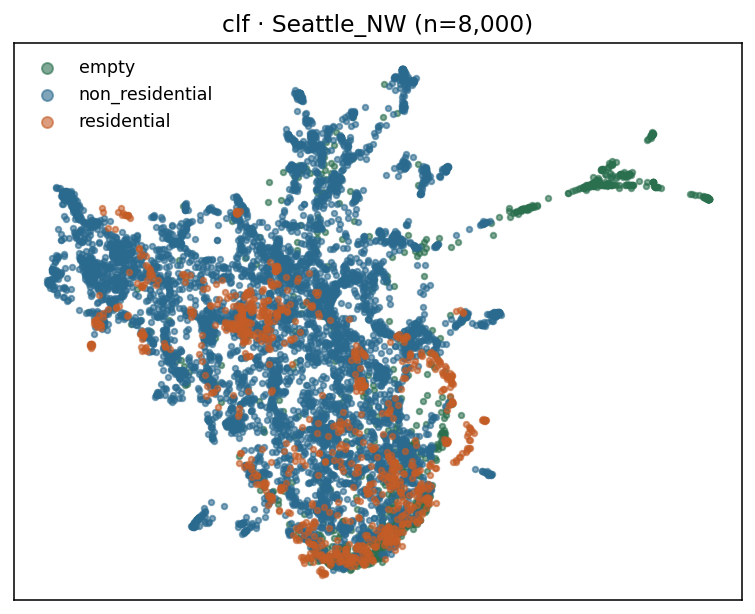

### Per-region UMAP (reg)

**Atlanta_SE**

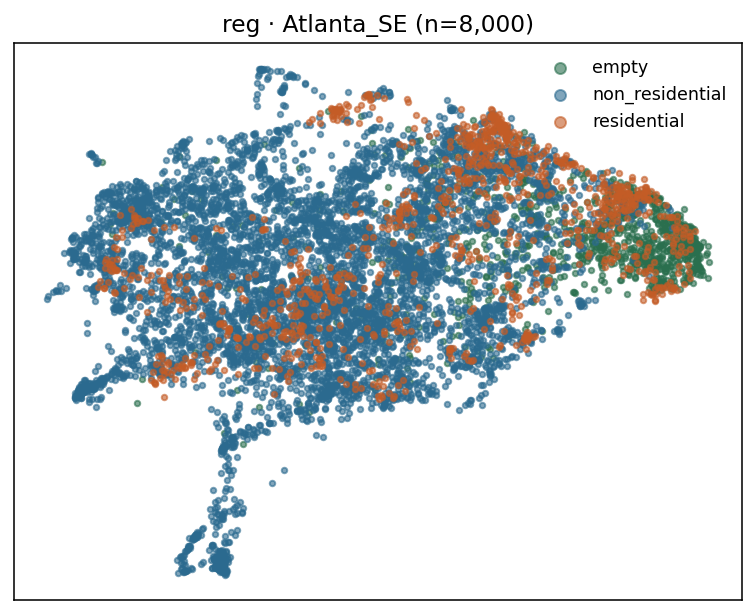

**Boston_NE**

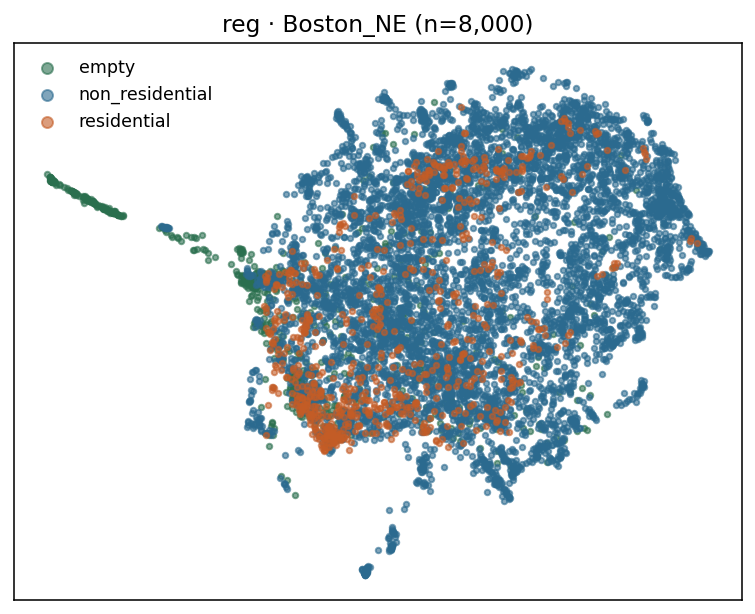

**Chicago_MW**

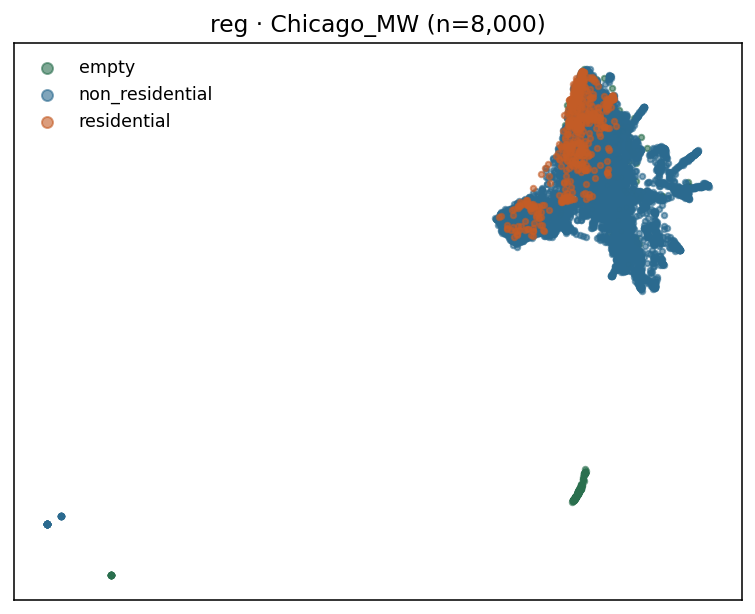

**Denver_W**

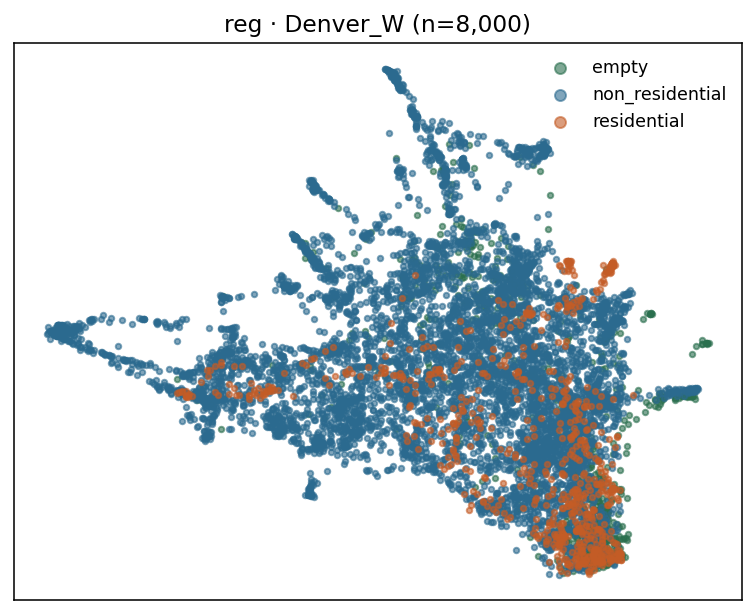

**Houston_S**

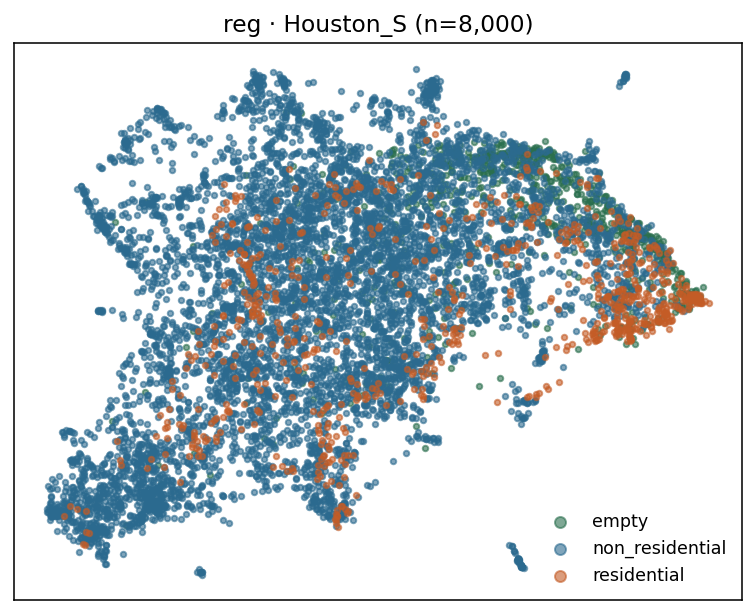

**LA_W**

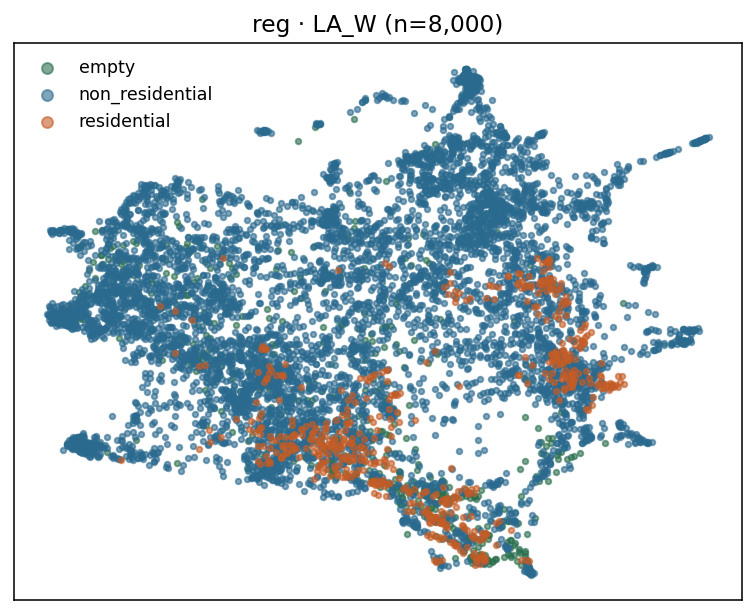

**NYC_NE**

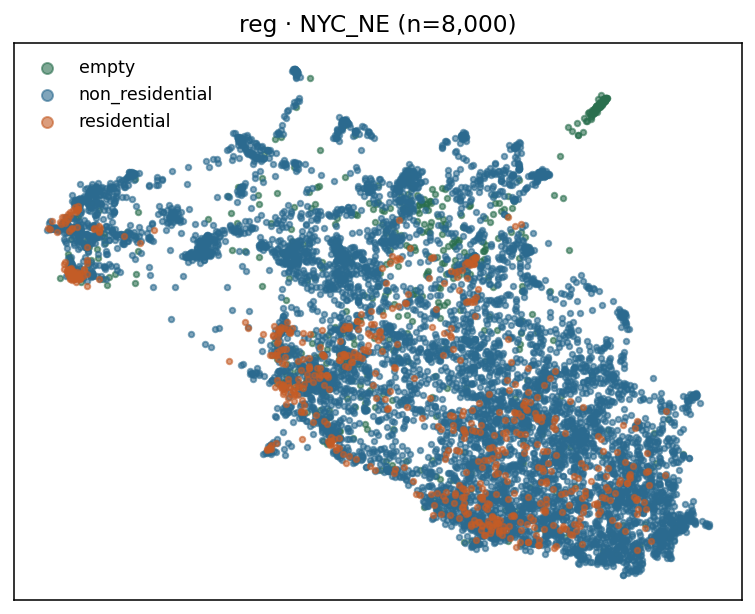

**Phoenix_SW**

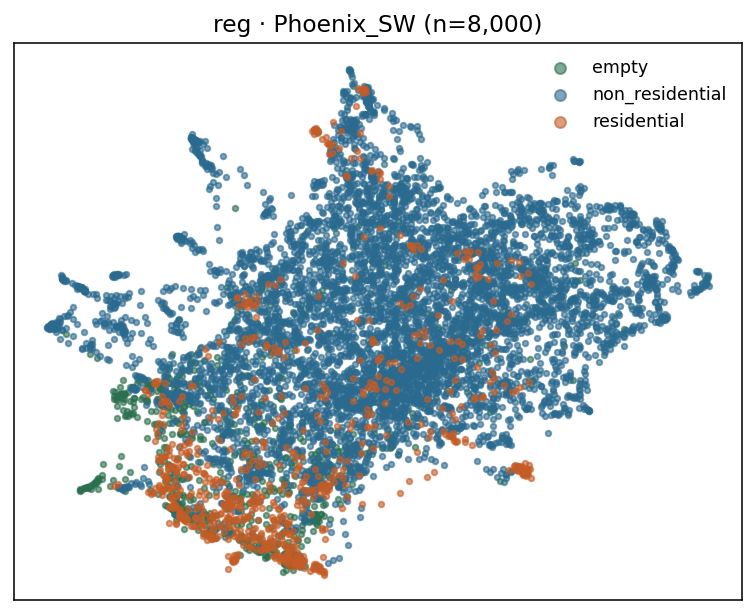

**SF_W**

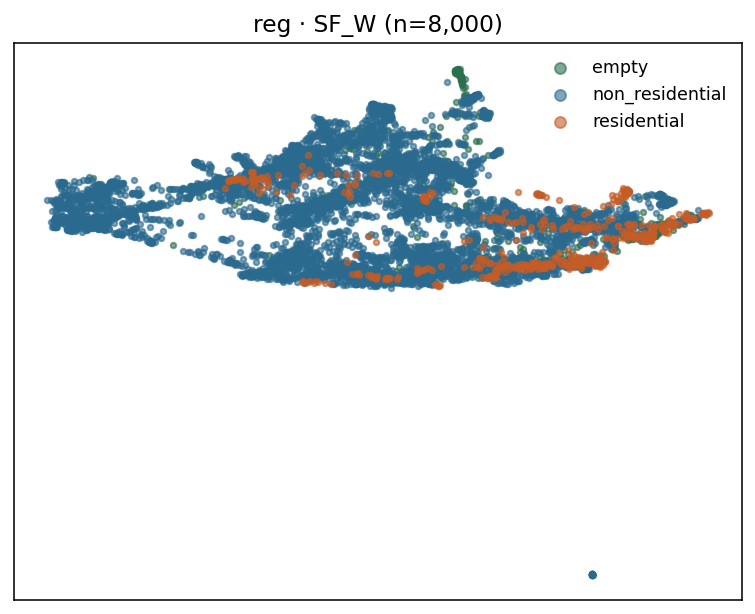

**Seattle_NW**

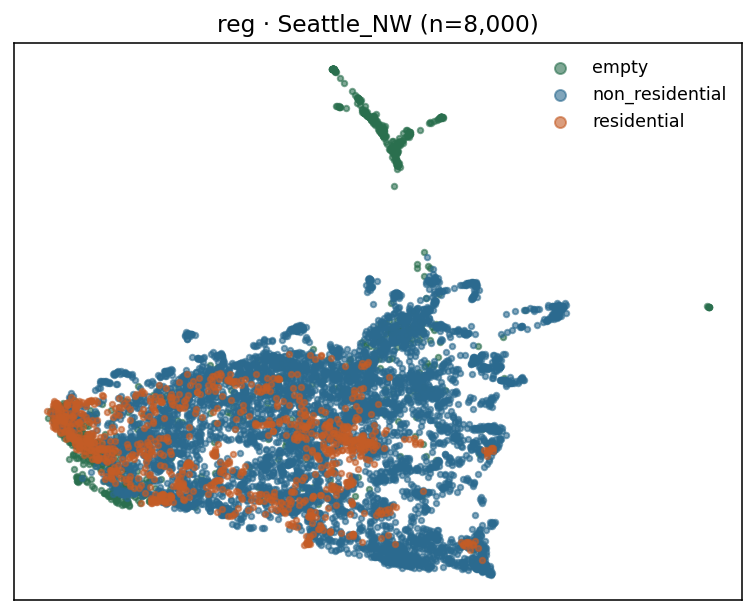

In [1]:
import json
from IPython.display import Image, Markdown, display
from pathlib import Path

K = 3
OUT = Path(f"outputs/week3_pixel_neighborhood_k{K}")
FIG = OUT / "figures"
if (OUT / "summary.json").exists():
    print(json.dumps(json.loads((OUT / "summary.json").read_text()), indent=2))
    for name in [
        "oof_confusion_clf_vs_reg.png",
        "loro_f1_clf_vs_reg.png",
        "delta_reg_minus_clf_by_city.png",
        "umap_clf_by_label_per_region.png",
        "umap_reg_by_label_per_region.png",
        "pca_clf_overview.png",
        "pca_reg_overview.png",
    ]:
        p = FIG / name
        if p.exists():
            display(Markdown(f"**{name}**"))
            display(Image(filename=str(p)))
    # per-metro panels
    for tag in ("clf", "reg"):
        d = FIG / f"umap_{tag}_by_label"
        if d.is_dir():
            display(Markdown(f"### Per-region UMAP ({tag})"))
            for p in sorted(d.glob("*.png")):
                display(Markdown(f"**{p.stem}**"))
                display(Image(filename=str(p)))
else:
    print("No summary yet — run training cells / CLI below.")


## UMAP on CNN pooled embeddings

OOF 128-D vectors from `NbCNN.encode` (masked GAP), LORO fold checkpoints.
Subsample 80k for UMAP speed. Rebuild:

```bash
.venv/bin/python -u scripts/extract_week3_neighborhood_umap.py --k 3
```


In [ ]:
# Refresh UMAP/PCA if missing
import subprocess, sys
need = ["umap_clf_by_label_per_region.png", "umap_reg_by_label_per_region.png"]
if not all((FIG / n).exists() for n in need):
    subprocess.check_call(
        [sys.executable, "-u", str(ROOT / "scripts" / "extract_week3_neighborhood_umap.py"),
         "--k", str(K), "--umap-only"],
        cwd=str(ROOT),
    )
for name in need:
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(FIG / name)))
for tag in ("clf", "reg"):
    d = FIG / f"umap_{tag}_by_label"
    display(Markdown(f"### {tag} per region"))
    for p in sorted(d.glob("*.png")):
        display(Markdown(f"**{p.stem}**"))
        display(Image(filename=str(p)))


## 0. Setup


In [ ]:
from __future__ import annotations
import json, multiprocessing as mp, os, subprocess, sys, warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path(".").resolve()
for _ in range(3):
    if (ROOT / "requirements.txt").exists():
        break
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

K = 3  # <-- ablation knob
DATA = ROOT / "datasets" / f"week3_pixel_neighborhood_k{K}"
OUT = ROOT / "outputs" / f"week3_pixel_neighborhood_k{K}"
FIG = OUT / "figures"
BUILDER = ROOT / "scripts" / "build_week3_pixel_neighborhoods.py"
TRAIN = ROOT / "scripts" / "train_week3_pixel_neighborhood_loro.py"

print(f"ROOT={ROOT}  K={K}  CUDA={torch.cuda.is_available()} n_gpu={torch.cuda.device_count()}")


## 1. Build / load neighborhood cache


In [ ]:
if not (DATA / "X_nb.npy").exists():
    subprocess.check_call(
        [sys.executable, "-u", str(BUILDER), "--k", str(K), "--workers", str(os.cpu_count() or 8)],
        cwd=str(ROOT),
    )
man = json.loads((DATA / "manifest.json").read_text())
print(json.dumps(man, indent=2))
X = np.load(DATA / "X_nb.npy", mmap_mode="r")
mask = np.load(DATA / "mask.npy", mmap_mode="r")
meta = pd.read_parquet(DATA / "meta.parquet")
print("X", X.shape, "mask", mask.shape, "meta", len(meta))
print(meta["label"].value_counts())


## 2. Model sketch


In [ ]:
from week3_pixel_neighborhood_trainlib import NbCNN, pack_input, EMB_DIM
x0 = pack_input(X[:2], mask[:2])
print("packed", x0.shape)  # (2, 65, k, k)
m = NbCNN(n_out=3)
with torch.no_grad():
    print("logits", m(torch.from_numpy(x0)).shape, "emb_dim", EMB_DIM)


## 3. Train LORO (GPU) — or load outputs


In [ ]:
# Prefer CLI for spawn+multi-GPU:
#   OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 \
#     .venv/bin/python -u scripts/train_week3_pixel_neighborhood_loro.py --k 3

if not (OUT / "summary.json").exists():
    subprocess.check_call(
        [sys.executable, "-u", str(TRAIN), "--k", str(K)],
        cwd=str(ROOT),
        env={**os.environ, "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1"},
    )
print(json.dumps(json.loads((OUT / "summary.json").read_text()), indent=2))
for name in [
    "oof_confusion_clf_vs_reg.png",
    "loro_f1_clf_vs_reg.png",
    "delta_reg_minus_clf_by_city.png",
]:
    display(Image(filename=str(OUT / "figures" / name)))
